In [8]:
# IMPORTANTE: Configurar HF_HOME ANTES de importar datasets
import os
os.environ['HF_HOME'] = '/media/datos1/tts-valenciano/huggingface'
os.environ['HF_DATASETS_CACHE'] = '/media/datos1/tts-valenciano/huggingface/datasets'

print(f"HF_HOME establecido en: {os.environ['HF_HOME']}")
print(f"HF_DATASETS_CACHE establecido en: {os.environ['HF_DATASETS_CACHE']}")

from datasets import load_dataset
import pandas as pd
import numpy as np
from huggingface_hub import login
from dotenv import load_dotenv

load_dotenv()

login(os.getenv("HUGGINGFACE_TOKEN"))

print("\nCargando dataset...")
dataset = load_dataset("javiimts/corts-valencianes-asr-parquet")

HF_HOME establecido en: /media/datos1/tts-valenciano/huggingface
HF_DATASETS_CACHE establecido en: /media/datos1/tts-valenciano/huggingface/datasets

Cargando dataset...

Cargando dataset...


Resolving data files:   0%|          | 0/81 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/77 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/81 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/77 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/71 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/68 [00:00<?, ?it/s]

### Particiones

In [2]:
print(f"Particiones del dataset: {dataset.keys()}")
print(dataset["clean_dev_short"])

Particiones del dataset: dict_keys(['clean_train_short', 'clean_test_short', 'clean_dev_short', 'other_train_short', 'other_test_short', 'other_dev_short', 'clean_train_long', 'clean_test_long', 'clean_dev_long', 'other_train_long', 'other_test_long', 'other_dev_long'])
Dataset({
    features: ['identifier', 'audio', 'segment_path', 'text'],
    num_rows: 1284
})


### Distribución de longitud

Analizando split: clean_train_short

Estadísticas de duración:
  Total de audios: 44,932
  Duración promedio: 9.79s (0.16m)
  Duración mínima: 0.18s
  Duración máxima: 41.74s (0.70m)
  Duración mediana: 8.24s
  Duración total: 122.15 horas

Estadísticas de duración:
  Total de audios: 44,932
  Duración promedio: 9.79s (0.16m)
  Duración mínima: 0.18s
  Duración máxima: 41.74s (0.70m)
  Duración mediana: 8.24s
  Duración total: 122.15 horas


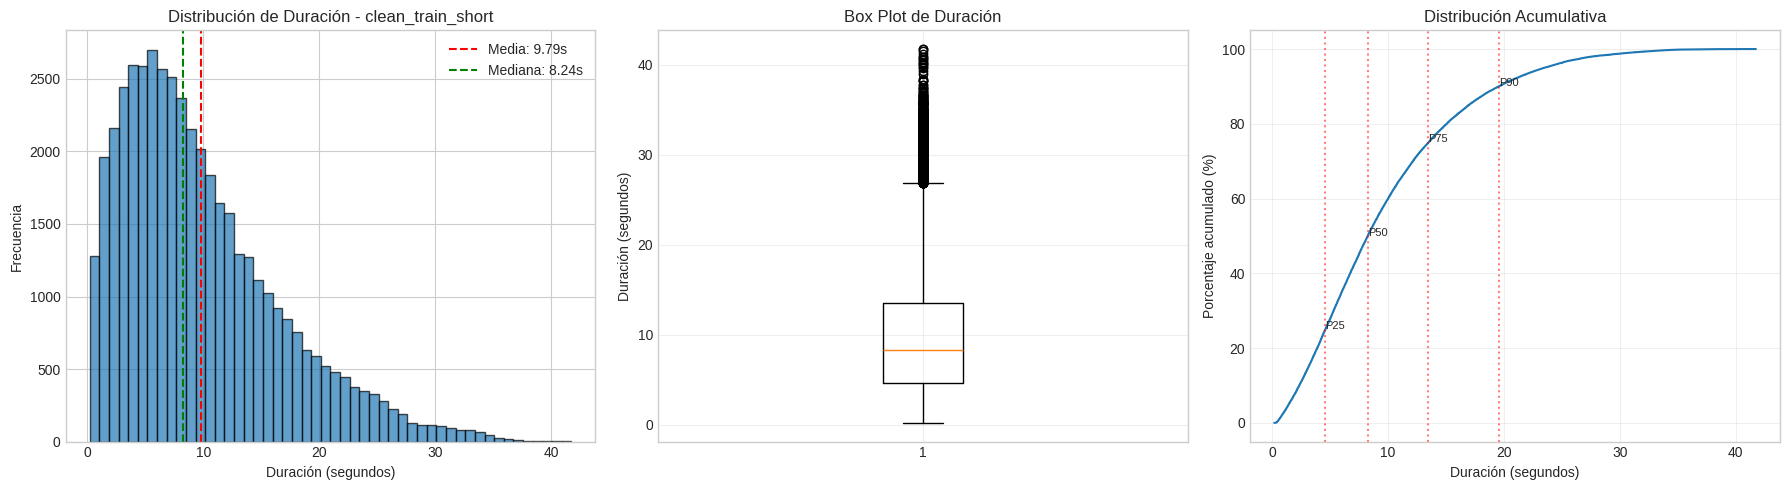

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Configurar el estilo
plt.rcParams['figure.figsize'] = (14, 6)
plt.style.use('seaborn-v0_8-whitegrid')

def plot_duration_distribution(dataset, split_name):
    """
    Crea gráficos de distribución de duración de audio para un split específico
    """
    print(f"Analizando split: {split_name}")

    # Obtener el split
    split_data = dataset[split_name]

    # Usamos .map() que si no tarda mucho en procesar!!
    def compute_duration(example):
        duration = len(example['audio']['array']) / example['audio']['sampling_rate']
        # Asegurarse de que sea float y no NaN
        if duration is None or np.isnan(duration):
            duration = 0.0
        return {'duration_seconds': float(duration)}

    # Agregar columna de duración al dataset
    split_with_duration = split_data.map(
        compute_duration,
        num_proc=4,  # evita problemas de paralelismo
        desc="Calculando duración",
        # remove_columns=['audio'] # descomentar si queremos mantener el audio para el análisis siguiente
    )

    # Extraer duraciones
    durations = np.array(split_with_duration['duration_seconds'])
    
    # Estadísticas usando numpy
    total = len(durations)
    mean_dur = np.mean(durations)
    min_dur = np.min(durations)
    max_dur = np.max(durations)
    median_dur = np.median(durations)
    total_hours = np.sum(durations) / 3600
    
    print(f"\nEstadísticas de duración:")
    print(f"  Total de audios: {total:,}")
    print(f"  Duración promedio: {mean_dur:.2f}s ({mean_dur/60:.2f}m)")
    print(f"  Duración mínima: {min_dur:.2f}s")
    print(f"  Duración máxima: {max_dur:.2f}s ({max_dur/60:.2f}m)")
    print(f"  Duración mediana: {median_dur:.2f}s")
    print(f"  Duración total: {total_hours:.2f} horas")
    
    # Crear subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # 1. Histograma
    axes[0].hist(durations, bins=50, edgecolor='black', alpha=0.7)
    axes[0].set_xlabel('Duración (segundos)')
    axes[0].set_ylabel('Frecuencia')
    axes[0].set_title(f'Distribución de Duración - {split_name}')
    axes[0].axvline(mean_dur, color='red', linestyle='--', label=f'Media: {mean_dur:.2f}s')
    axes[0].axvline(median_dur, color='green', linestyle='--', label=f'Mediana: {median_dur:.2f}s')
    axes[0].legend()
    
    # 2. Box plot
    axes[1].boxplot(durations, vert=True)
    axes[1].set_ylabel('Duración (segundos)')
    axes[1].set_title('Box Plot de Duración')
    axes[1].grid(True, alpha=0.3)
    
    # 3. Distribución acumulativa
    sorted_durations = np.sort(durations)
    cumulative = np.arange(1, len(sorted_durations) + 1) / len(sorted_durations) * 100
    axes[2].plot(sorted_durations, cumulative)
    axes[2].set_xlabel('Duración (segundos)')
    axes[2].set_ylabel('Porcentaje acumulado (%)')
    axes[2].set_title('Distribución Acumulativa')
    axes[2].grid(True, alpha=0.3)
    
    # Añadir líneas para percentiles comunes
    for pct in [25, 50, 75, 90]:
        val = np.percentile(durations, pct)
        axes[2].axvline(val, color='red', linestyle=':', alpha=0.5)
        axes[2].text(val, pct, f'P{pct}', fontsize=8)
    
    plt.tight_layout()
    plt.show()
    
    return split_with_duration



split_to_analyze = "clean_train_short"
dataset_with_durations = plot_duration_distribution(dataset, split_to_analyze)

### Análisis para entrenamiento

Vamos a analizar cuántos audios quedarían si filtramos por duración óptima para TTS:

In [4]:
# Analizar rangos óptimos para entrenamiento TTS
durations = np.array(dataset_with_durations['duration_seconds'])

# Definir rangos. Me he guiado un poco por los rangos que hay en LJSpeech y paper
ranges = {
    'very_short': (0, 1), 
    'optimal': (1, 15),
    'long': (15, 20),
    'very_long': (20, float('inf'))
}

print("Distribución por rangos de duración:\n")
print("="*60)
for label, (min_dur, max_dur) in ranges.items():
    count = np.sum((durations >= min_dur) & (durations < max_dur))
    percentage = (count / len(durations)) * 100
    total_hours = np.sum(durations[(durations >= min_dur) & (durations < max_dur)]) / 3600
    print(f"{label:20s}: {count:6,} audios ({percentage:5.1f}%) - {total_hours:6.2f} horas")

# Calcular el rango ideal (5-15s según StyleTTS2 paper)
ideal_count = np.sum((durations >= ranges["optimal"][0]) & (durations <= ranges["optimal"][1]))
ideal_percentage = (ideal_count / len(durations)) * 100
ideal_hours = np.sum(durations[(durations >= ranges["optimal"][0]) & (durations <= ranges["optimal"][1])]) / 3600

print(f"\n Rango IDEAL para StyleTTS2:")
print(f"   {ideal_count:,} audios ({ideal_percentage:.1f}%) - {ideal_hours:.2f} horas")

Distribución por rangos de duración:

very_short          :  1,236 audios (  2.8%) -   0.24 horas
optimal             : 34,635 audios ( 77.1%) -  69.68 horas
long                :  4,883 audios ( 10.9%) -  23.35 horas
very_long           :  4,178 audios (  9.3%) -  28.89 horas

 Rango IDEAL para StyleTTS2:
   34,635 audios (77.1%) - 69.68 horas


### Análisis de calidad de audio (ruido)

In [5]:
import librosa
import numpy as np

# Aquí podríamos haber usado ClearVoice pero ya lo tenemos hecho así que de momento lo dejamos así
# Aquí también podemos ver referencias de las distintas métricas: https://github.com/modelscope/ClearerVoice-Studio/tree/main/speechscore
def compute_snr_simple(audio_array, sample_rate, top_db=30):
    """
    Calcula SNR simple estimando el ruido del audio
    
    Args:
        audio_array: Array de audio
        sample_rate: Sampling rate
        top_db: Threshold para detectar silencio
    
    Returns:
        SNR estimado en dB (mayor = menos ruido)
    """
    # Detectar segmentos de silencio (asumimos que son ruido)
    intervals = librosa.effects.split(audio_array, top_db=top_db)
    
    if len(intervals) == 0:
        return 0  # Todo es silencio/ruido
    
    # Separar señal y ruido
    signal_mask = np.zeros_like(audio_array, dtype=bool)
    for start, end in intervals:
        signal_mask[start:end] = True
    
    signal = audio_array[signal_mask]
    noise = audio_array[~signal_mask]
    
    if len(noise) == 0:
        return 100  # No hay ruido detectable
    
    # Calcular potencias
    signal_power = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)
    
    if noise_power == 0:
        return 100
    
    # SNR en dB
    snr = 10 * np.log10(signal_power / noise_power)
    return snr


# Probar con un audio del dataset
example = dataset_with_durations[0]
audio_array = example['audio']['array']
sample_rate = example['audio']['sampling_rate']

snr = compute_snr_simple(audio_array, sample_rate)
print(f"SNR estimado del primer audio: {snr:.2f} dB")


SNR estimado del primer audio: 22.55 dB


#### Análisis DNSMOS

In [14]:
from pprint import pprint
import numpy as np
import librosa
import tempfile
import os
import soundfile as sf
import importlib
import speechscore.scores.dnsmos.dnsmos as dnsmos_module
import speechscore.speechscore as speechscore_module
importlib.reload(dnsmos_module)
importlib.reload(speechscore_module)
from speechscore import SpeechScore

# Inicializar SpeechScore solo con la métrica DNSMOS (no requiere audio de referencia)
dns_evaluator = SpeechScore(['DNSMOS'])

# Evaluar el primer audio del dataset
example = dataset_with_durations[0]
audio_array = example['audio']['array']
sample_rate = example['audio']['sampling_rate']

print(f"Analizando audio: {example['identifier']}")
print(f"Duración: {len(audio_array) / sample_rate:.2f}s")
print(f"Sample rate original: {sample_rate} Hz")

# DNSMOS requiere 16kHz
if sample_rate != 16000:
    print(f"\n Resampling de {sample_rate}Hz a 16kHz...")
    audio_array = librosa.resample(audio_array, orig_sr=sample_rate, target_sr=16000)
    sample_rate = 16000

# Guardar temporalmente el audio porque SpeechScore opera sobre rutas
with tempfile.NamedTemporaryFile(suffix=".wav", delete=False) as tmp_wav:
    sf.write(tmp_wav.name, audio_array, sample_rate)
    temp_audio_path = tmp_wav.name

try:
    print("\nCalculando DNSMOS con SpeechScore...")
    scores = dns_evaluator(
        test_path=temp_audio_path,
        reference_path=None,
        window=None,
        score_rate=sample_rate,
        return_mean=False
    )
finally:
    os.remove(temp_audio_path)

dns_scores = scores['DNSMOS']
ovrl = dns_scores['OVRL']
sig = dns_scores['SIG']
bak = dns_scores['BAK']
p808 = dns_scores['P808_MOS']

print("\n" + "="*60)
print("RESULTADOS DNSMOS (SpeechScore)")
print("="*60)
print(f"OVRL (Overall): {ovrl:.2f} (1-5, donde 5 = mejor)")
print(f"SIG (Signal):   {sig:.2f} (claridad de la señal)")
print(f"BAK (Background): {bak:.2f} (calidad del fondo/ruido)")
print(f"P808:          {p808:.2f}")

print("Detalle libreria:")
pprint(scores)

Analizando audio: 777d0be485c32fc946d21f5b13eebf5e
Duración: 17.35s
Sample rate original: 16000 Hz

Calculando DNSMOS con SpeechScore...

RESULTADOS DNSMOS (SpeechScore)
OVRL (Overall): 2.06 (1-5, donde 5 = mejor)
SIG (Signal):   2.62 (claridad de la señal)
BAK (Background): 2.49 (calidad del fondo/ruido)
P808:          3.07
Detalle libreria:
{'DNSMOS': {'BAK': np.float64(2.491967480772367),
            'OVRL': np.float64(2.0615006282458537),
            'P808_MOS': np.float32(3.065184),
            'SIG': np.float64(2.619487331874513)}}

RESULTADOS DNSMOS (SpeechScore)
OVRL (Overall): 2.06 (1-5, donde 5 = mejor)
SIG (Signal):   2.62 (claridad de la señal)
BAK (Background): 2.49 (calidad del fondo/ruido)
P808:          3.07
Detalle libreria:
{'DNSMOS': {'BAK': np.float64(2.491967480772367),
            'OVRL': np.float64(2.0615006282458537),
            'P808_MOS': np.float32(3.065184),
            'SIG': np.float64(2.619487331874513)}}


#### Análisis de calidad para toda la partición

In [5]:
from speechmos import dnsmos
import librosa
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

def analyze_audio_quality(dataset_with_durations, sample_size=None):
    """
    Calcula DNSMOS para todos los audios (o una muestra) del dataset
    
    Args:
        dataset_with_durations: Dataset con columna duration_seconds
        sample_size: Número de audios a analizar (None = todos)
    """
    
    # Determinar cuántos audios analizar
    total = len(dataset_with_durations)
    if sample_size is not None and sample_size < total:
        # Tomar muestra aleatoria
        indices = np.random.choice(total, sample_size, replace=False)
        print(f"Analizando muestra de {sample_size} audios de {total} totales...")
    else:
        indices = range(total)
        print(f"Analizando todos los {total} audios...")
    
    results = {
        'ovrl': [],
        'sig': [],
        'bak': [],
        'p808': [],
        'identifier': [],
        'duration': []
    }
    
    # Procesar cada audio
    for idx in tqdm(indices, desc="Calculando DNSMOS"):
        example = dataset_with_durations[int(idx)]
        audio_array = example['audio']['array']
        sample_rate = example['audio']['sampling_rate']
        
        # Resample si es necesario
        if sample_rate != 16000:
            audio_array = librosa.resample(audio_array, orig_sr=sample_rate, target_sr=16000)
        
        # Calcular DNSMOS
        try:
            scores = dnsmos.run(audio_array, sr=16000, verbose=False)
            
            results['ovrl'].append(scores['ovrl_mos'])
            results['sig'].append(scores['sig_mos'])
            results['bak'].append(scores['bak_mos'])
            results['p808'].append(scores['p808_mos'])
            results['identifier'].append(example['identifier'])
            results['duration'].append(example['duration_seconds'])
        except Exception as e:
            print(f"Error en audio {example['identifier']}: {e}")
            continue
    
    # Convertir a arrays numpy
    for key in ['ovrl', 'sig', 'bak', 'p808', 'duration']:
        results[key] = np.array(results[key])
    
    return results


def plot_quality_distribution(results, split_name):
    """
    Visualiza la distribución de calidad de audio
    """
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    metrics = [
        ('ovrl', 'OVRL (Overall Quality)', 'Calidad General'),
        ('sig', 'SIG (Signal Quality)', 'Calidad de Señal'),
        ('bak', 'BAK (Background Quality)', 'Calidad de Fondo'),
        ('p808', 'P808 MOS', 'MOS P.808')
    ]
    
    for ax, (key, title, label) in zip(axes.flat, metrics):
        data = results[key]
        
        # Histograma
        ax.hist(data, bins=30, edgecolor='black', alpha=0.7)
        ax.set_xlabel(label)
        ax.set_ylabel('Frecuencia')
        ax.set_title(f'{title} - {split_name}')
        
        # Líneas de estadísticas
        mean_val = np.mean(data)
        median_val = np.median(data)
        ax.axvline(mean_val, color='red', linestyle='--', label=f'Media: {mean_val:.2f}')
        ax.axvline(median_val, color='green', linestyle='--', label=f'Mediana: {median_val:.2f}')
        ax.legend()
        
        # Añadir texto con stats
        stats_text = f'Min: {np.min(data):.2f}\nMax: {np.max(data):.2f}\nStd: {np.std(data):.2f}'
        ax.text(0.02, 0.98, stats_text, transform=ax.transAxes, 
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    plt.show()
    
    # Estadísticas resumen

    print("="*60)
    for key, title, label in metrics:
        data = results[key]
        print(f"\n{title}:")
        print(f"  Media: {np.mean(data):.2f}")
        print(f"  Mediana: {np.median(data):.2f}")
        print(f"  Mín: {np.min(data):.2f}")
        print(f"  Máx: {np.max(data):.2f}")
        print(f"  Std: {np.std(data):.2f}")
    
    # Categorizar audios por calidad OVRL
    ovrl = results['ovrl']
    excellent = np.sum(ovrl > 4.0)
    good = np.sum((ovrl > 3.5) & (ovrl <= 4.0))
    acceptable = np.sum((ovrl > 3.0) & (ovrl <= 3.5))
    poor = np.sum(ovrl <= 3.0)
    
    print("\n" + "="*60)
    print("DISTRIBUCIÓN POR CALIDAD (OVRL)")
    print("="*60)
    total = len(ovrl)
    print(f"Excelente (> 4.0):   {excellent:5d} audios ({excellent/total*100:5.1f}%)")
    print(f"Buena (3.5-4.0):     {good:5d} audios ({good/total*100:5.1f}%)")
    print(f"Aceptable (3.0-3.5): {acceptable:5d} audios ({acceptable/total*100:5.1f}%)")
    print(f"Pobre (< 3.0):       {poor:5d} audios ({poor/total*100:5.1f}%)")


Analizando muestra de 100 audios de 44932 totales...


Calculando DNSMOS:   0%|          | 0/100 [00:00<?, ?it/s]

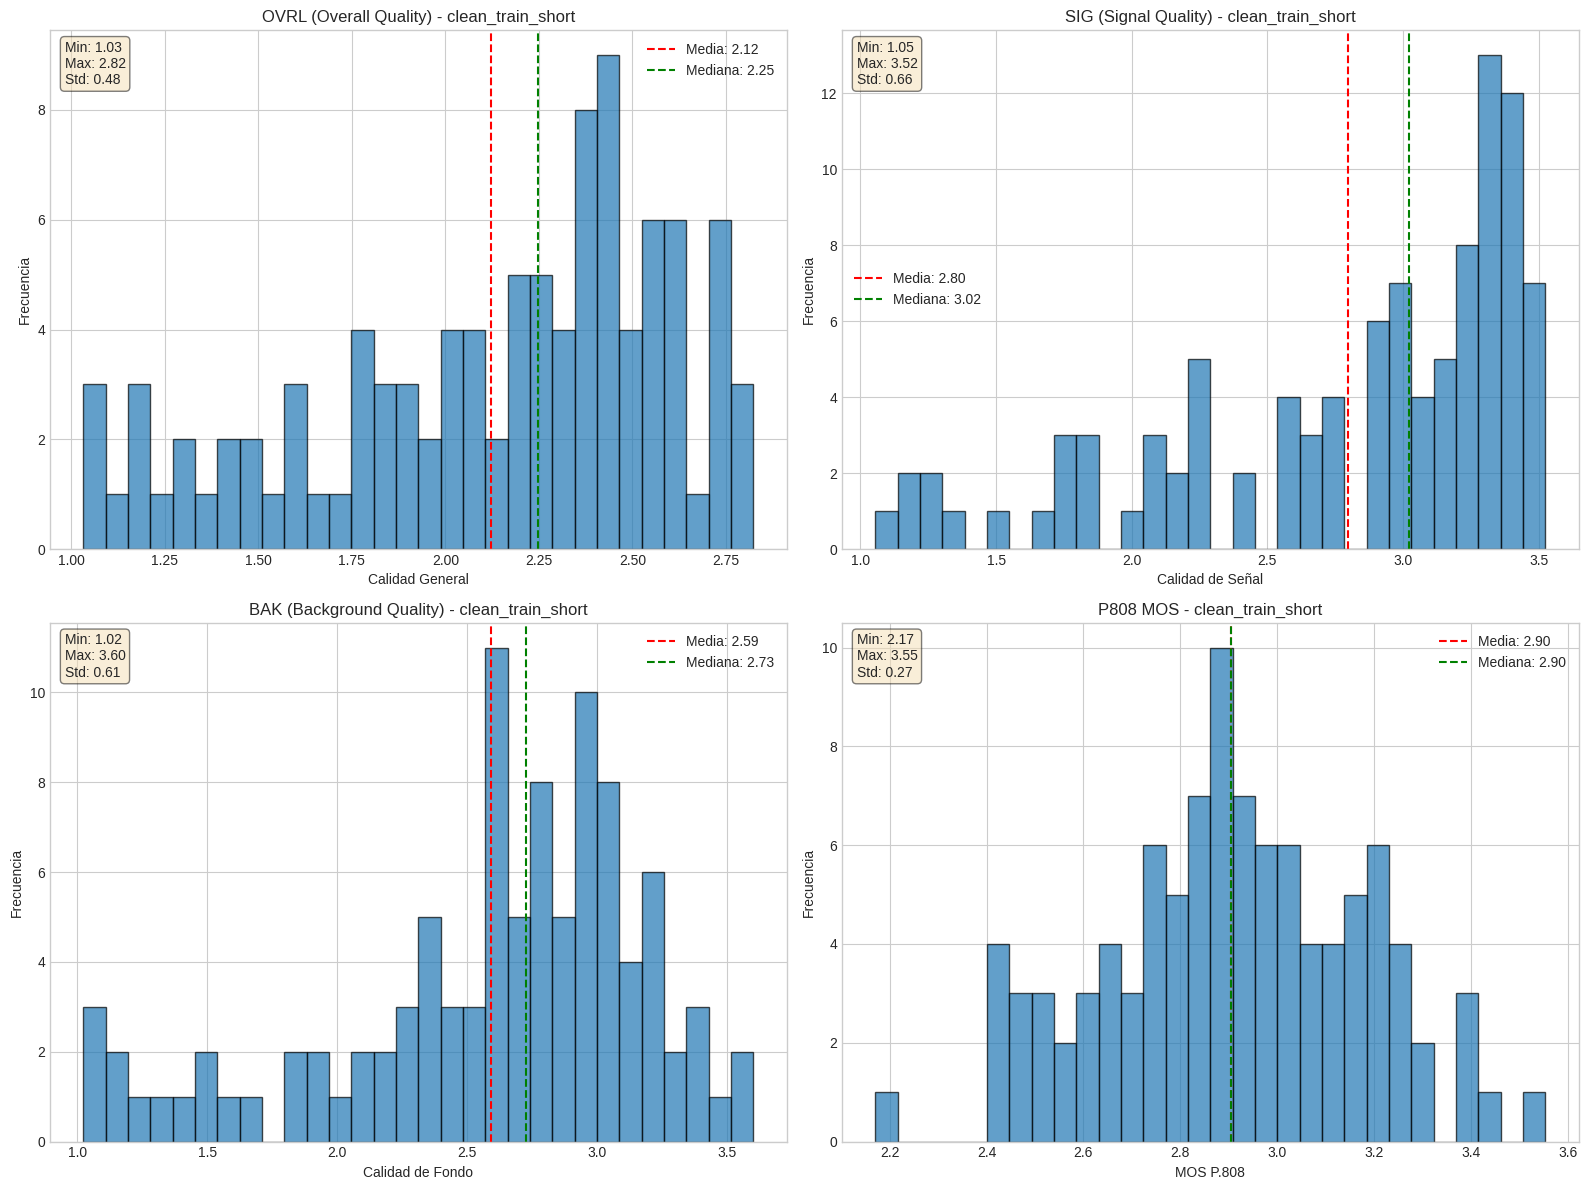


OVRL (Overall Quality):
  Media: 2.12
  Mediana: 2.25
  Mín: 1.03
  Máx: 2.82
  Std: 0.48

SIG (Signal Quality):
  Media: 2.80
  Mediana: 3.02
  Mín: 1.05
  Máx: 3.52
  Std: 0.66

BAK (Background Quality):
  Media: 2.59
  Mediana: 2.73
  Mín: 1.02
  Máx: 3.60
  Std: 0.61

P808 MOS:
  Media: 2.90
  Mediana: 2.90
  Mín: 2.17
  Máx: 3.55
  Std: 0.27

DISTRIBUCIÓN POR CALIDAD (OVRL)
Excelente (> 4.0):       0 audios (  0.0%)
Buena (3.5-4.0):         0 audios (  0.0%)
Aceptable (3.0-3.5):     0 audios (  0.0%)
Pobre (< 3.0):         100 audios (100.0%)


In [8]:
split_name = "clean_train_short" 
sample_size = 100  
results = analyze_audio_quality(dataset_with_durations, sample_size=sample_size)
plot_quality_distribution(results, split_name)

### (INCOMPLETO) Mejorar audio con Mel-Band-Roboformer-Vocal-Model

In [ ]:
!uv pip install -r ./Mel-Band-Roformer-Vocal-Model/requirements.txt
# TODO: Mover esto para que sea un modulo con pyproject

Resolved 82 packages in 2.48s                                        
   Building antlr4-python3-runtime==4.9.3                              
   Building antlr4-python3-runtime==4.9.3                      
   Building pretrainedmodels==0.7.4
   Building antlr4-python3-runtime==4.9.3                      
   Building pretrainedmodels==0.7.4
   Building efficientnet-pytorch==0.7.1
   Building antlr4-python3-runtime==4.9.3                      
   Building pretrainedmodels==0.7.4
   Building efficientnet-pytorch==0.7.1
⠙ Preparing packages... (0/13)
   Building antlr4-python3-runtime==4.9.3     0 B/104.23 KiB   
   Building pretrainedmodels==0.7.4
   Building efficientnet-pytorch==0.7.1
⠙ Preparing packages... (0/13)
   Building antlr4-python3-runtime==4.9.3     0 B/104.23 KiB   
   Building pretrainedmodels==0.7.4
   Building efficientnet-pytorch==0.7.1
⠙ Preparing packages... (0/13)
einops                      ------------------------------     0 B/41.24 KiB
   Building antlr4-python3-r

In [10]:
import soundfile as sf
from tqdm.notebook import tqdm

def store_partition_audios_melbandroformer(dataset, partition_name, tmp_input_folder="./melband_input_audios"):
    """
    Guarda los audios de una partición del dataset en una carpeta temporal para procesarlos con Mel-Band-Roformer.

    Args:
        dataset: Dataset de HuggingFace
        partition_name: Nombre de la partición a procesar (e.g., 'clean_dev_short')
    """

    partition = dataset[partition_name]

    for idx in tqdm(range(len(partition)), desc="Mejorando audios"):
        example = partition[int(idx)]
        audio_array = example['audio']['array']
        sample_rate = example['audio']['sampling_rate']

        # Guardar audio temporalmente
        temp_input_path = f"{tmp_input_folder}/{idx}.wav"
        sf.write(temp_input_path, audio_array, sample_rate)
    

store_partition_audios_melbandroformer(dataset, "clean_dev_short", "/media/datos1/tts-valenciano/tmp_in")

Mejorando audios:   0%|          | 0/1284 [00:00<?, ?it/s]

In [16]:
# Guardamos todos los audios que queramos procesar en una carpeta llamada "input_audios"
!cd ./Mel-Band-Roformer-Vocal-Model/ && python inference.py --config_path configs/config_vocals_mel_band_roformer.yaml --model_path MelBandRoformer.ckpt --input_folder /media/datos1/tts-valenciano/tmp_in --store_dir /media/datos1/tts-valenciano/tmp_out

Using model: MelBandRoformer.ckpt
Traceback (most recent call last):
  File "/home/calia/styletts2-valenciano/t2/Mel-Band-Roformer-Vocal-Model/inference.py", line 124, in <module>
    proc_folder(None)
  File "/home/calia/styletts2-valenciano/t2/Mel-Band-Roformer-Vocal-Model/inference.py", line 111, in proc_folder
    model = model.to(device)
  File "/home/calia/styletts2-valenciano/t2/.venv/lib/python3.10/site-packages/torch/nn/modules/module.py", line 1371, in to
    return self._apply(convert)
  File "/home/calia/styletts2-valenciano/t2/.venv/lib/python3.10/site-packages/torch/nn/modules/module.py", line 930, in _apply
    module._apply(fn)
  File "/home/calia/styletts2-valenciano/t2/.venv/lib/python3.10/site-packages/torch/nn/modules/module.py", line 930, in _apply
    module._apply(fn)
  File "/home/calia/styletts2-valenciano/t2/.venv/lib/python3.10/site-packages/torch/nn/modules/module.py", line 930, in _apply
    module._apply(fn)
  [Previous line repeated 3 more times]
  File "

### (INCOMPLETO) Mejora de calidad con ClearVoice

In [3]:
from clearvoice import ClearVoice
import soundfile as sf
import numpy as np
import os
import IPython.display as ipd
from tqdm.notebook import tqdm

# Inicializar ClearVoice con MossFormer2
print("Inicializando ClearVoice con MossFormerGAN_SE_16K")
# myClearVoice = ClearVoice(task='speech_enhancement', model_names=['MossFormerGAN_SE_16K'])

# myClearVoice

def enhance_speech_in_partition(dataset, partition_name):
    """
    Mejora el habla en todos los audios de una partición del dataset usando ClearVoice.
    
    Args:
        dataset: Dataset de HuggingFace
        partition_name: Nombre de la partición a procesar (e.g., 'clean_dev_short')
    """
    myClearVoice = ClearVoice(task='speech_enhancement', model_names=['MossFormerGAN_SE_16K'])
    
    partition = dataset[partition_name]

    for idx in tqdm(range(len(partition)), desc="Mejorando audios"):
        example = partition[int(idx)]
        audio_array = example['audio']['array']
        sample_rate = example['audio']['sampling_rate']
        
        # Guardar audio temporalmente
        temp_input_path = f"/tmp/{example['identifier']}_input.wav"
        temp_output_path = f"/tmp/{example['identifier']}_output.wav"
        sf.write(temp_input_path, audio_array, sample_rate)
        
        # Procesar con ClearVoice
        enhanced_audio = myClearVoice(input_path=temp_input_path, online_write=False)
        
        print(enhanced_audio)

        break
        # Guardar audio mejorado
        myClearVoice.write(enhanced_audio, output_path=temp_output_path)
        
        example['segment_path'] = temp_output_path

        # Sobreescribir el audio en el dataset (opcional)
        example['audio']['array'] = enhanced_audio
        example['audio']['sampling_rate'] = sample_rate
    
    return dataset[partition_name]

enhance_speech_in_partition(dataset, "clean_dev_short")




Inicializando ClearVoice con MossFormerGAN_SE_16K


Mejorando audios:   0%|          | 0/1284 [00:00<?, ?it/s]

Running MossFormerGAN_SE_16K ...


  0%|          | 0/1 [00:00<?, ?it/s]


OutOfMemoryError: CUDA out of memory. Tried to allocate 80.00 MiB. GPU 0 has a total capacity of 23.64 GiB of which 46.69 MiB is free. Process 2733210 has 1.70 GiB memory in use. Process 2733230 has 1.70 GiB memory in use. Process 2733211 has 1.70 GiB memory in use. Process 2733229 has 2.44 GiB memory in use. Process 2737214 has 15.15 GiB memory in use. Including non-PyTorch memory, this process has 894.00 MiB memory in use. Of the allocated memory 675.86 MiB is allocated by PyTorch, and 10.14 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

#### Comparar calidad antes/después

In [28]:
from speechmos import dnsmos
import librosa
import IPython.display as ipd

# Cargar ambos audios
print("Cargando audios para comparación...")
original, sr_orig = sf.read(input_path)
enhanced, sr_enh = sf.read(output_path)

print(f"Audio original: {len(original)} samples @ {sr_orig} Hz")
print(f"Audio mejorado: {len(enhanced)} samples @ {sr_enh} Hz")

# Calcular DNSMOS para ambos
print("\n" + "="*60)
print("EVALUANDO CALIDAD CON DNSMOS")
print("="*60)

# Resamplear a 16kHz si es necesario
if sr_orig != 16000:
    print("\nResampling audio original a 16kHz...")
    original_16k = librosa.resample(original, orig_sr=sr_orig, target_sr=16000)
else:
    original_16k = original

if sr_enh != 16000:
    print("Resampling audio mejorado a 16kHz...")
    enhanced_16k = librosa.resample(enhanced, orig_sr=sr_enh, target_sr=16000)
else:
    enhanced_16k = enhanced

# Evaluar original
print("\n📊 Audio ORIGINAL:")
scores_orig = dnsmos.run(original_16k, sr=16000, verbose=False)
print(f"  OVRL: {scores_orig['ovrl_mos']:.2f}")
print(f"  SIG:  {scores_orig['sig_mos']:.2f}")
print(f"  BAK:  {scores_orig['bak_mos']:.2f}")
print(f"  P808: {scores_orig['p808_mos']:.2f}")

# Evaluar mejorado
print("\n✨ Audio MEJORADO:")
scores_enh = dnsmos.run(enhanced_16k, sr=16000, verbose=False)
print(f"  OVRL: {scores_enh['ovrl_mos']:.2f} (Δ {scores_enh['ovrl_mos'] - scores_orig['ovrl_mos']:+.2f})")
print(f"  SIG:  {scores_enh['sig_mos']:.2f} (Δ {scores_enh['sig_mos'] - scores_orig['sig_mos']:+.2f})")
print(f"  BAK:  {scores_enh['bak_mos']:.2f} (Δ {scores_enh['bak_mos'] - scores_orig['bak_mos']:+.2f})")
print(f"  P808: {scores_enh['p808_mos']:.2f} (Δ {scores_enh['p808_mos'] - scores_orig['p808_mos']:+.2f})")

print("\n" + "="*60)

# Mostrar mejora
improvement = scores_enh['ovrl_mos'] - scores_orig['ovrl_mos']
if improvement > 0.5:
    print("🎉 MEJORA SIGNIFICATIVA!")
elif improvement > 0.2:
    print("👍 Mejora moderada")
elif improvement > 0:
    print("✓ Ligera mejora")
else:
    print("⚠️ Sin mejora notable")

# Reproducir audios para comparar auditivamente
print("\n🔊 Reproducir para comparar:")
print("\nAudio ORIGINAL:")
display(ipd.Audio(original, rate=sr_orig))

print("\nAudio MEJORADO:")
display(ipd.Audio(enhanced, rate=sr_enh))

Cargando audios para comparación...
Audio original: 325052 samples @ 16000 Hz
Audio mejorado: 325052 samples @ 16000 Hz

EVALUANDO CALIDAD CON DNSMOS

📊 Audio ORIGINAL:
  OVRL: 2.65
  SIG:  3.28
  BAK:  3.27
  P808: 3.40

✨ Audio MEJORADO:
  OVRL: 2.65
  SIG:  3.28
  BAK:  3.27
  P808: 3.40

✨ Audio MEJORADO:
  OVRL: 2.21 (Δ -0.44)
  SIG:  2.68 (Δ -0.60)
  BAK:  3.84 (Δ +0.56)
  P808: 3.33 (Δ -0.08)

⚠️ Sin mejora notable

🔊 Reproducir para comparar:

Audio ORIGINAL:
  OVRL: 2.21 (Δ -0.44)
  SIG:  2.68 (Δ -0.60)
  BAK:  3.84 (Δ +0.56)
  P808: 3.33 (Δ -0.08)

⚠️ Sin mejora notable

🔊 Reproducir para comparar:

Audio ORIGINAL:


Cargando audios para comparación...
Audio original: 325052 samples @ 16000 Hz
Audio mejorado: 325052 samples @ 16000 Hz

EVALUANDO CALIDAD CON DNSMOS

📊 Audio ORIGINAL:
  OVRL: 2.65
  SIG:  3.28
  BAK:  3.27
  P808: 3.40

✨ Audio MEJORADO:
  OVRL: 2.65
  SIG:  3.28
  BAK:  3.27
  P808: 3.40

✨ Audio MEJORADO:
  OVRL: 2.21 (Δ -0.44)
  SIG:  2.68 (Δ -0.60)
  BAK:  3.84 (Δ +0.56)
  P808: 3.33 (Δ -0.08)

⚠️ Sin mejora notable

🔊 Reproducir para comparar:

Audio ORIGINAL:
  OVRL: 2.21 (Δ -0.44)
  SIG:  2.68 (Δ -0.60)
  BAK:  3.84 (Δ +0.56)
  P808: 3.33 (Δ -0.08)

⚠️ Sin mejora notable

🔊 Reproducir para comparar:

Audio ORIGINAL:


Cargando audios para comparación...
Audio original: 325052 samples @ 16000 Hz
Audio mejorado: 325052 samples @ 16000 Hz

EVALUANDO CALIDAD CON DNSMOS

📊 Audio ORIGINAL:
  OVRL: 2.65
  SIG:  3.28
  BAK:  3.27
  P808: 3.40

✨ Audio MEJORADO:
  OVRL: 2.65
  SIG:  3.28
  BAK:  3.27
  P808: 3.40

✨ Audio MEJORADO:
  OVRL: 2.21 (Δ -0.44)
  SIG:  2.68 (Δ -0.60)
  BAK:  3.84 (Δ +0.56)
  P808: 3.33 (Δ -0.08)

⚠️ Sin mejora notable

🔊 Reproducir para comparar:

Audio ORIGINAL:
  OVRL: 2.21 (Δ -0.44)
  SIG:  2.68 (Δ -0.60)
  BAK:  3.84 (Δ +0.56)
  P808: 3.33 (Δ -0.08)

⚠️ Sin mejora notable

🔊 Reproducir para comparar:

Audio ORIGINAL:



Audio MEJORADO:


#### Aplicar ClearVoice a una partición completa

In [ ]:
# Ejemplo: Aplicar ClearVoice con GPU por lotes (MUCHO MÁS RÁPIDO)
# Esta partición tiene ~2,700 ejemplos

# IMPORTANTE: Asegúrate de haber ejecutado la celda que carga myClearVoice

# Configurar batch_size (ajustar según memoria GPU)
# Recomendación: 16-32 para 8GB VRAM, 64-128 para 12GB+
batch_size = 32

# Procesar partición de desarrollo con batches
dataset_enhanced = apply_clearvoice_batched(dataset, 'clean_dev_short', batch_size=batch_size)

# Después de procesar, puedes guardar el dataset mejorado:
# dataset_enhanced.push_to_hub("javiimts/corts-valencianes-asr-parquet-enhanced")

# O procesar la partición de entrenamiento (más grande):
# dataset_enhanced = apply_clearvoice_batched(dataset_enhanced, 'clean_train_short', batch_size=batch_size)  # 44,932 ejemplos



Procesando partición (single GPU): clean_dev_short
Total de ejemplos: 1284

Iniciando procesamiento secuencial...
Nota: Esto puede tardar, pero evita problemas con CUDA multiprocessing


Mejorando clean_dev_short:   0%|          | 0/1284 [00:00<?, ? examples/s]

Running MossFormer2_SE_48K ...


100%|██████████| 1/1 [00:00<00:00,  3.41it/s]



Running MossFormer2_SE_48K ...


100%|██████████| 1/1 [00:00<00:00,  6.85it/s]



... (37 outputs left out)

100%|██████████| 1/1 [00:00<00:00,  6.82it/s]



Running MossFormer2_SE_48K ...


  0%|          | 0/1 [00:00<?, ?it/s]



KeyboardInterrupt: 